In [1]:
import pandas as pd 

import numpy as np 

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import f1_score, balanced_accuracy_score, matthews_corrcoef

import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv('train_barcode.csv')
data = data.set_index('Sample')

target = data.loc[:, "Species"]
target = target.replace({"Pk": 1, "Pv": 0}).astype(int) 
data_predictors = data.loc[:, data.columns != 'Species']

/tmp/ipykernel_437/2578482164.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  target = target.replace({"Pk": 1, "Pv": 0}).astype(int)


In [3]:
test_data = pd.read_csv('test_barcode.csv')
test_data = test_data.set_index('Sample')

y_test = test_data.loc[:, "Species"]
y_test = y_test.replace({"Pk": 1, "Pv": 0}).astype(int) 
x_test = test_data.loc[:, test_data.columns != 'Species']

/tmp/ipykernel_437/1357762790.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test = y_test.replace({"Pk": 1, "Pv": 0}).astype(int)


In [4]:
def gb_test(features): 
    f1_scores = [] 
    for train_rows, held_out_rows in folds.split(data_predictors, target):
        
        x_fold = data_predictors.iloc[train_rows][features]
        y_fold = target.iloc[train_rows]

        gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, subsample=0.75, max_depth=2, random_state=42)
        
        gb.fit(x_fold, y_fold)
    
        y_pred = gb.predict(x_test[features])
        
        value = f1_score(y_test, y_pred)
        
        f1_scores.append(value)
        
    return np.mean(f1_scores)

In [5]:
mrmr_barcode_scores = {}

barcode_lengths = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for length in barcode_lengths: 
    with open(f"MRMR_subsets/top_{length}_MRMR") as f:
        features = f.read().splitlines()
    score = gb_test(features)
    mrmr_barcode_scores[length] = score 


In [6]:
moremore = []
for length in barcode_lengths: 
    qual = mrmr_barcode_scores[length]
    moremore.append(qual)
    
moremore

[0.984126984126984,
 0.9873015873015873,
 0.9904761904761905,
 0.9904761904761905,
 0.9904761904761905,
 0.9904761904761905,
 0.9904761904761905,
 0.9904761904761905,
 0.9904761904761905,
 0.9904761904761905]

In [7]:
gb_barcode_scores = {}

for length in barcode_lengths: 
    with open(f"GB_subsets/top_{length}_GB.txt") as f:
        features = f.read().splitlines()
    score = gb_test(features)
    gb_barcode_scores[length] = score 

In [8]:
greatb = []
for length in barcode_lengths: 
    qual = gb_barcode_scores[length]
    greatb.append(qual)
    
greatb

[0.9904761904761905, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [9]:
ga_barcode_scores = {}

for length in barcode_lengths: 
    with open(f"GA_subsets/top_{length}_GA.txt") as f:
        features = f.read().splitlines()
    score = gb_test(features)
    ga_barcode_scores[length] = score 

In [10]:
goona = []
for length in barcode_lengths: 
    qual = ga_barcode_scores[length]
    goona.append(qual)
    
goona

[1.0, 0.9968253968253968, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [11]:
with open("GA_subsets/top_75_GA.txt") as f:
        sevfiv = f.read().splitlines()
        
with open("GA_subsets/top_100_GA.txt") as f:
        hund = f.read().splitlines()

In [12]:
with open("GA_subsets_2/top_75_GA.txt") as f:
        sevfiv_2 = f.read().splitlines()
        
with open("GA_subsets_2/top_100_GA.txt") as f:
        hund_2 = f.read().splitlines()

In [13]:
res = list(set(hund) & set(hund_2))
len(res)

1

In [14]:
res = list(set(hund) & set(sevfiv))
len(res)

2

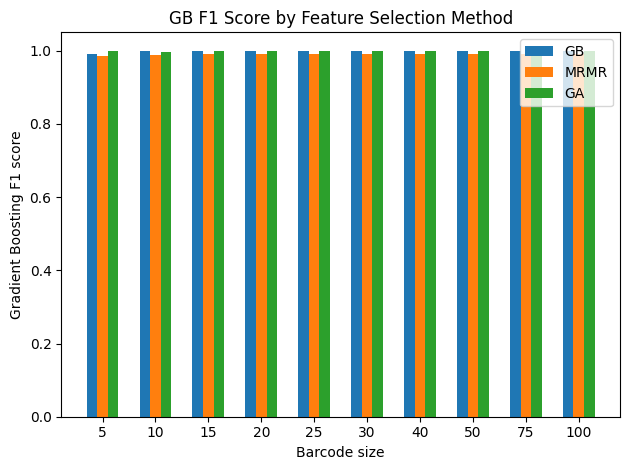

In [15]:
# Bar positions and width
x = np.arange(len(barcode_lengths))
width = 0.2

# Plot bars
plt.bar(x - width, gb_barcode_scores.values(), width, label='GB')
plt.bar(x, mrmr_barcode_scores.values(), width, label='MRMR')
plt.bar(x + width, ga_barcode_scores.values(), width, label='GA')

# Labels and formatting
plt.xlabel('Barcode size')
plt.ylabel('Gradient Boosting F1 score')
plt.title('GB F1 Score by Feature Selection Method')
plt.xticks(x, barcode_lengths)
plt.legend()
plt.tight_layout()

plt.savefig('GB_scores')